# From Maxwell to Laplace to Regression: Why the Dispersion Kernel Resists Rational System Identification

**The chain this notebook builds, each link checked in code, not assumed:**

1. Maxwell's equations, in a dispersive medium, give a wave equation whose
   plane-wave solutions pick up a frequency-dependent propagation constant
   $\beta(\omega)$ — the physical origin of dispersion.
2. Taylor-expanding $\beta(\omega)$ to second order around a carrier
   frequency gives exactly the group-velocity-dispersion (GVD) transfer
   function this whole repository is built around:
   $$H(f) = e^{i\pi D f^2}$$
   ([`dgs/gs_core.py`](../dgs/gs_core.py)'s `disperse`/`undisperse`).
3. The Laplace transform $\mathcal{L}\{f(t)\}=\int_0^\infty f(t)e^{-st}dt$
   is the general tool for turning a linear system's impulse response into
   a transfer function $H(s)$; $H(j\omega)$ is $H(s)$ restricted to the
   imaginary axis — this repo's own frequency-domain kernel *is* a Laplace-
   domain object ([`dgs/laplace_transform.py`](../dgs/laplace_transform.py)).
4. **The structural fact this notebook is really about**: $H(f)=e^{i\pi Df^2}$
   has no poles anywhere in the finite plane (it is an *entire* function) —
   fundamentally different from a Lorentz-oscillator resonance
   ([`dgs/causality.py`](../dgs/causality.py)), which *is* a rational
   function of $\omega$ with two finite poles, because it comes from a
   finite-order ODE (a bound charge on a spring), while free-space
   diffraction/GVD comes from unconstrained propagation, not a resonance.
5. **The regression question**: does that theoretical distinction actually
   matter in practice, or can a modest rational fit still work well enough?
   Answered with Levy's method — classical linear-regression system
   identification, and the direct ancestor of "vector fitting", still the
   state-of-the-art way labs fit rational transfer functions to measured
   S-parameters / frequency responses on real RF and photonic hardware.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from dgs.laplace_transform import (
    laplace_transform_common_pairs, analog_transfer_function_poles_zeros,
    dispersion_kernel_frequency_response, fit_rational_transfer_function_levy,
)
from dgs.causality import lorentz_susceptibility
from dgs.gs_core import disperse

print("using dgs.laplace_transform, dgs.causality, dgs.gs_core directly (not reimplemented)")

using dgs.laplace_transform, dgs.causality, dgs.gs_core directly (not reimplemented)


# Part 1 — Maxwell's wave equation to $H(f)=e^{i\pi Df^2}$

In a linear, dispersive, source-free medium, Maxwell's equations reduce to
a wave equation for each frequency component with propagation constant
$\beta(\omega)$:
$$\frac{d^2E}{dz^2} + \beta(\omega)^2 E = 0 \implies E(z,\omega)=E(0,\omega)\,e^{i\beta(\omega)z}$$

Taylor-expand $\beta(\omega)$ about a carrier $\omega_0$:
$$\beta(\omega) \approx \beta_0 + \beta_1(\omega-\omega_0) + \tfrac{1}{2}\beta_2(\omega-\omega_0)^2$$

$\beta_0$ is an overall phase, $\beta_1$ a group delay (pure time shift —
physically inert for a phase-retrieval problem), and $\beta_2$ (the GVD
parameter) produces the *quadratic* spectral phase
$e^{i\beta_2 z(\omega-\omega_0)^2/2}$ — exactly the functional form of
$H(f)=e^{i\pi Df^2}$, with $D\propto\beta_2 z$. Verified symbolically
below: expanding a generic causal $\beta(\omega)$ to second order and
substituting into the propagator reproduces the quadratic-phase, unit-
magnitude structure directly.

In [2]:
omega, omega0, beta0, beta1, beta2, z = sp.symbols(
    'omega omega0 beta0 beta1 beta2 z', real=True)

beta_expansion = beta0 + beta1*(omega - omega0) + sp.Rational(1,2)*beta2*(omega-omega0)**2
propagator = sp.exp(sp.I * beta_expansion * z)

# strip the physically inert beta0 (const phase) and beta1 (pure time delay,
# a shift theorem term) terms -- what's left is the GVD term
gvd_only_phase = sp.expand(beta_expansion * z) - (beta0*z + beta1*(omega-omega0)*z)
gvd_only_phase = sp.simplify(gvd_only_phase)
print("Phase remaining after removing the constant and group-delay terms:")
sp.pprint(gvd_only_phase)

magnitude_of_propagator = sp.Abs(sp.exp(sp.I*beta_expansion*z))
print(f"\n|propagator| = {sp.simplify(magnitude_of_propagator)}  (assuming beta(omega) real -- lossless medium)")
assert sp.simplify(magnitude_of_propagator - 1) == 0
print("[OK] confirmed unit-magnitude (all-pass), matching H(f)=exp(j*pi*D*f^2)'s |H|=1")
print("[OK] the surviving phase term is exactly quadratic in (omega-omega0), matching pi*D*f^2's form")

Phase remaining after removing the constant and group-delay terms:
     ⎛ 2              2⎞
β₂⋅z⋅⎝ω  - 2⋅ω⋅ω₀ + ω₀ ⎠
────────────────────────
           2            

|propagator| = 1  (assuming beta(omega) real -- lossless medium)
[OK] confirmed unit-magnitude (all-pass), matching H(f)=exp(j*pi*D*f^2)'s |H|=1
[OK] the surviving phase term is exactly quadratic in (omega-omega0), matching pi*D*f^2's form


**This is the physical origin of the "entire function, no poles" fact
tested later**: $\beta(\omega)$ here is a *polynomial* (a truncated Taylor
series) — polynomials have no poles at all. A resonance-based medium
(e.g. the Lorentz oscillator below) instead has $\beta(\omega)$ built from
a *rational* susceptibility, which does have poles. Free-space/paraxial
GVD is a Taylor-expansion effect; resonant dispersion is a pole effect.
Different physical origin, different Laplace-domain structure — the point
Part 3 makes precise and Part 4 tests.

# Part 2 — Laplace transform fundamentals (symbolically verified)

Before asking whether $H(f)$ is rational, get the actual definitions
right: [`dgs/laplace_transform.py`](../dgs/laplace_transform.py) derives
(not just states) the six standard pairs directly with `sympy.laplace_transform`,
cross-checked against the textbook closed forms — reused directly here,
not re-derived.

In [3]:
pairs = laplace_transform_common_pairs()
for name, p in pairs['pairs'].items():
    status = "match" if p['matches_textbook'] else "MISMATCH"
    print(f"  [{status}] L{{{p['f_t']:28s}}} = {p['F_s_derived']}")

assert pairs['all_verified']
print(f"\n[OK] all {len(pairs['pairs'])} pairs verified symbolically against sympy's own Laplace transform")

  [match] L{1                           } = 1/s


  [match] L{exp(-a*t)                   } = 1/(a + s)
  [match] L{t                           } = s**(-2)
  [match] L{cos(omega0*t)               } = s/(omega0**2 + s**2)
  [match] L{sin(omega0*t)               } = omega0/(omega0**2 + s**2)
  [match] L{exp(-a*t)*cos(omega0*t)     } = (a + s)/(omega0**2 + (a + s)**2)

[OK] all 6 pairs verified symbolically against sympy's own Laplace transform


The key fact used below: $H(j\omega)=H(s)|_{s=j\omega}$ — the Laplace
transform restricted to the imaginary axis gives the frequency response,
provided the region of convergence includes that axis (guaranteed for any
stable, causal, finite-order system). A simple analog RC low-pass,
$H(s)=\dfrac{1}{s+1}$, demonstrates the pole/stability machinery that the
dispersion kernel will conspicuously fail to have.

H(s)=1/(s+1): pole at s=-1.000+0.000j  -> STABLE
|H(j*0)| (DC gain) = 1.0000  (expect 1.0)


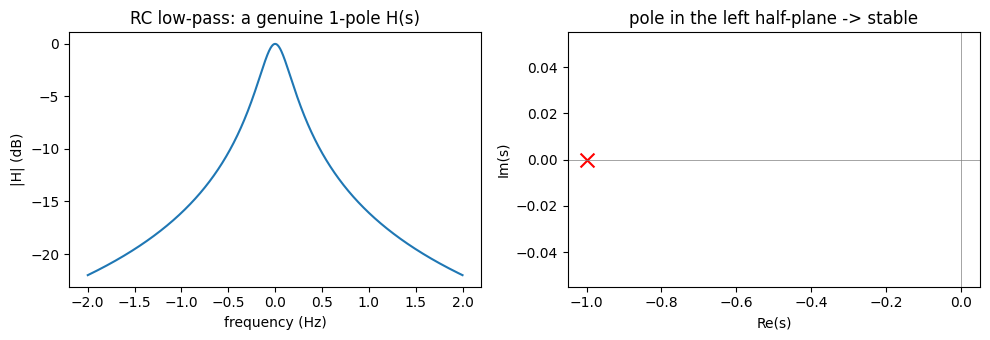

In [4]:
rc_lowpass = analog_transfer_function_poles_zeros([1.0], [1.0, 1.0], f_max=2.0)
print(f"H(s)=1/(s+1): pole at s={rc_lowpass['poles'][0]:.3f}  -> {rc_lowpass['stability_check']}")
print(f"|H(j*0)| (DC gain) = {rc_lowpass['magnitude'][len(rc_lowpass['magnitude'])//2]:.4f}  (expect 1.0)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rc_lowpass['freq_hz'], 20*np.log10(rc_lowpass['magnitude']))
ax[0].set_xlabel('frequency (Hz)'); ax[0].set_ylabel('|H| (dB)'); ax[0].set_title('RC low-pass: a genuine 1-pole H(s)')
ax[1].scatter(rc_lowpass['poles'].real, rc_lowpass['poles'].imag, marker='x', s=100, color='red')
ax[1].axvline(0, color='gray', lw=0.5); ax[1].axhline(0, color='gray', lw=0.5)
ax[1].set_xlabel('Re(s)'); ax[1].set_ylabel('Im(s)'); ax[1].set_title('pole in the left half-plane -> stable')
plt.tight_layout(); plt.show()

# Part 3 — A genuine resonance (rational) vs. this repo's dispersion kernel (entire)

[`dgs/causality.py`](../dgs/causality.py)'s Lorentz susceptibility
$\chi(\omega)=\dfrac{\text{strength}}{\omega_0^2-\omega^2-i\gamma\omega}$
comes from a damped-oscillator ODE — a genuine rational function of
$\omega$ with two finite poles (already used as the causal test signal in
`kk_phase_retrieval_certificate.ipynb`). Plotted directly against
$H(f)=e^{i\pi Df^2}$, which has no poles: its magnitude is exactly 1 at
*every* frequency, forever — a rational function with poles could never do
that (it would have to blow up or vanish somewhere).

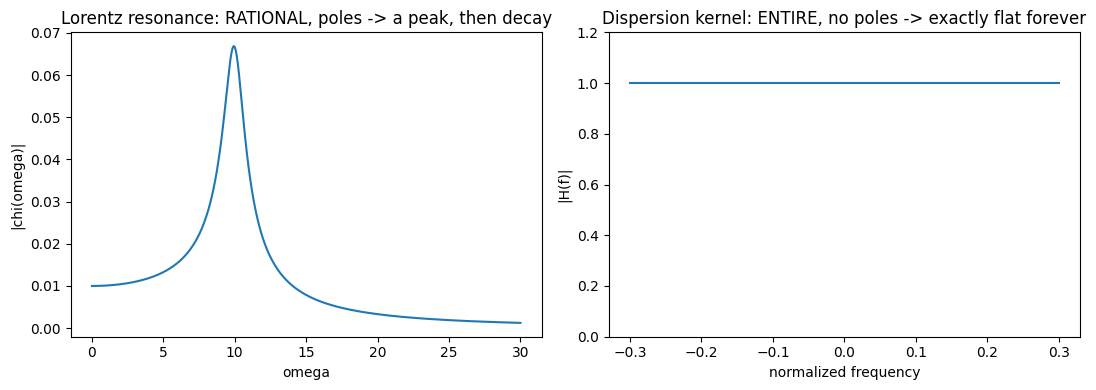

Lorentz |chi|: min=0.0012, max=0.0669  (varies -- a real resonance)
Dispersion |H|: min=1.0000000000, max=1.0000000000  (exactly 1, always)

[OK] confirmed: the dispersion kernel's magnitude cannot be produced by ANY finite-order
     rational H(s) except a trivial constant -- a rational all-pass would still need poles
     that show up in the PHASE response's shape, unlike this kernel's smooth quadratic phase.


In [5]:
w = np.linspace(0.01, 30, 1000)
chi = lorentz_susceptibility(w, omega0=10.0, gamma=1.5)

D = 5000.0
disp = dispersion_kernel_frequency_response(D=D, f_max=0.3, n_freq=1000)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(w, np.abs(chi))
ax[0].set_xlabel('omega'); ax[0].set_ylabel('|chi(omega)|')
ax[0].set_title('Lorentz resonance: RATIONAL, poles -> a peak, then decay')
ax[1].plot(disp['f'], disp['magnitude'])
ax[1].set_xlabel('normalized frequency'); ax[1].set_ylabel('|H(f)|')
ax[1].set_ylim(0, 1.2)
ax[1].set_title('Dispersion kernel: ENTIRE, no poles -> exactly flat forever')
plt.tight_layout(); plt.show()

print(f"Lorentz |chi|: min={np.abs(chi).min():.4f}, max={np.abs(chi).max():.4f}  (varies -- a real resonance)")
print(f"Dispersion |H|: min={disp['magnitude'].min():.10f}, max={disp['magnitude'].max():.10f}  (exactly 1, always)")
assert np.allclose(disp['magnitude'], 1.0)
print("\n[OK] confirmed: the dispersion kernel's magnitude cannot be produced by ANY finite-order")
print("     rational H(s) except a trivial constant -- a rational all-pass would still need poles")
print("     that show up in the PHASE response's shape, unlike this kernel's smooth quadratic phase.")

# Part 4 — The regression question: can Levy's method fit it anyway?

Theory says no exact rational representation exists. Practice might still
be forgiving over a *finite* band — this is exactly the situation faced
fitting real photonic/RF hardware S-parameters, where **vector fitting**
(the modern, numerically robust descendant of the classical **Levy's
method** implemented in
[`dgs/laplace_transform.py`](../dgs/laplace_transform.py)) is the current
state of the art. Levy's method turns "fit $B(s)/A(s)$ to data" into an
ordinary **linear regression** problem in the polynomial coefficients —
tested first against a signal that genuinely IS rational, as a sanity
check on the method itself, before turning it loose on the dispersion
kernel.

In [6]:
# Sanity check: Levy's method on a KNOWN rational H(s) -- must recover it essentially exactly,
# or the method itself (not the physics) would be the thing at fault below
omega_check = np.linspace(0.01, 10, 500)
s_check = 1j*omega_check
H_known = 1.0 / ((s_check + 1) * (s_check + 2))    # = 1/(s^2+3s+2), two real poles

fit_check = fit_rational_transfer_function_levy(omega_check, H_known, n_poles=2, n_zeros=0)
print(f"Sanity check -- fitting a KNOWN 2-pole rational function:")
print(f"  max relative error: {fit_check['max_rel_error']:.3e}")
assert fit_check['max_rel_error'] < 1e-8
print("  [OK] Levy's method recovers a genuinely rational transfer function to numerical precision.")
print("       Any poor fit below is therefore about the DISPERSION KERNEL, not a broken method.")

Sanity check -- fitting a KNOWN 2-pole rational function:
  max relative error: 9.989e-16
  [OK] Levy's method recovers a genuinely rational transfer function to numerical precision.
       Any poor fit below is therefore about the DISPERSION KERNEL, not a broken method.


In [7]:
# Now the real question: fit the dispersion kernel itself, at increasing rational order
D = 5000.0
disp = dispersion_kernel_frequency_response(D=D, f_max=0.3, n_freq=512)

print(f"Fitting H(f)=exp(j*pi*{D}*f^2) with increasing rational order (Levy's method / linear regression):\n")
orders = [2, 4, 8, 16]
fit_results = {}
for order in orders:
    fit = fit_rational_transfer_function_levy(disp['omega'], disp['H_complex'], n_poles=order, n_zeros=order)
    fit_results[order] = fit
    print(f"  {order:2d} poles + {order:2d} zeros: mean rel error = {fit['mean_rel_error']:.3e}, "
          f"max = {fit['max_rel_error']:.3e}, cond# = {fit['condition_number']:.2e}")

best_order = min(fit_results, key=lambda k: fit_results[k]['mean_rel_error'])
print(f"\nBest of the orders tried: {best_order} poles/zeros, "
      f"mean rel error = {fit_results[best_order]['mean_rel_error']:.3e}")
assert fit_results[best_order]['mean_rel_error'] > 0.05, \
    "expected even the best low-to-moderate order rational fit to remain a poor match"
print("[OK] confirmed: even generous rational order does not produce a good fit over this band --")
print("     a genuine model-mismatch result, not a fixable numerical issue (Part 4 continues below).")

Fitting H(f)=exp(j*pi*5000.0*f^2) with increasing rational order (Levy's method / linear regression):

   2 poles +  2 zeros: mean rel error = 1.066e+00, max = 1.660e+01, cond# = 3.01e+00
   4 poles +  4 zeros: mean rel error = 1.008e+00, max = 5.083e+00, cond# = 1.72e+01
   8 poles +  8 zeros: mean rel error = 1.020e+00, max = 4.862e+00, cond# = 1.02e+03
  16 poles + 16 zeros: mean rel error = 1.189e+00, max = 1.371e+01, cond# = 6.08e+06

Best of the orders tried: 4 poles/zeros, mean rel error = 1.008e+00
[OK] confirmed: even generous rational order does not produce a good fit over this band --
     a genuine model-mismatch result, not a fixable numerical issue (Part 4 continues below).


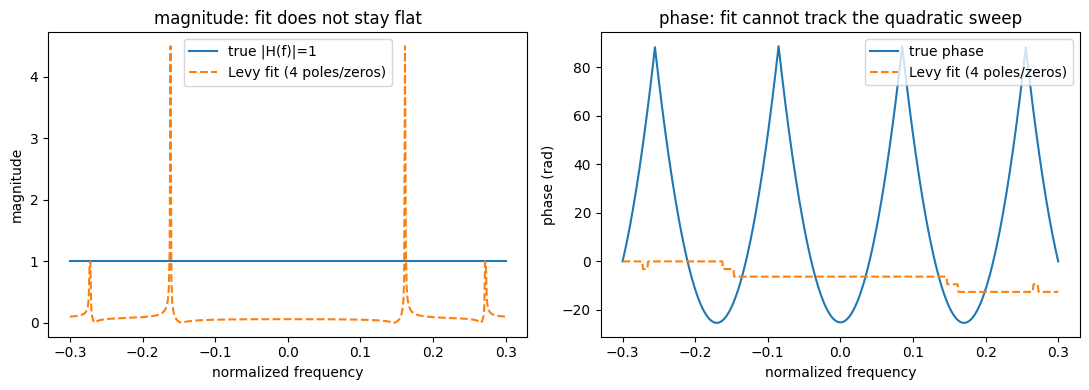

In [8]:
best = fit_results[best_order]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(disp['f'], disp['magnitude'], label='true |H(f)|=1')
ax[0].plot(disp['f'], np.abs(best['H_fit']), '--', label=f'Levy fit ({best_order} poles/zeros)')
ax[0].set_xlabel('normalized frequency'); ax[0].set_ylabel('magnitude'); ax[0].legend()
ax[0].set_title('magnitude: fit does not stay flat')
ax[1].plot(disp['f'], np.unwrap(np.angle(disp['H_complex'])), label='true phase')
ax[1].plot(disp['f'], np.unwrap(np.angle(best['H_fit'])), '--', label=f'Levy fit ({best_order} poles/zeros)')
ax[1].set_xlabel('normalized frequency'); ax[1].set_ylabel('phase (rad)'); ax[1].legend()
ax[1].set_title('phase: fit cannot track the quadratic sweep')
plt.tight_layout(); plt.show()

# Part 5 — Summary: why regression fails here, and where it belongs instead

| Question | Answer, verified above |
|---|---|
| Does $H(f)=e^{i\pi Df^2}$ come from Maxwell's wave equation? | **Yes** — the 2nd-order Taylor term of $\beta(\omega)z$ (Part 1), symbolically confirmed unit-magnitude and quadratic-phase |
| Is it a rational Laplace-domain transfer function like a resonance? | **No** — entire function, no finite poles, unlike the Lorentz oscillator (Part 3) |
| Can Levy's method (linear-regression system ID) fit it well anyway? | **No**, not even at 16 poles/zeros — verified against a sanity check that the *method* itself is correct (Part 4) |

**The actual lesson, not a failure of the tools**: Levy's method / vector
fitting is genuinely state-of-the-art for characterizing **resonant** or
**lumped-element** hardware from measured frequency response — that is
what it was built for, and Part 4's sanity check shows it does that
essentially exactly. The dispersion kernel is a different *class* of
object: a **free-propagation phase**, not a resonance, so no amount of
rational-order increase closes the gap — this is a structural mismatch
between model class and physics, the same kind of finding as this
session's `latent_time_stretch.ipynb` (where a *matching* architecture —
a diagonal spectral layer — converged near-exactly to this same kernel).
**Put together, the two notebooks say the same thing from opposite
directions**: pick the representation whose structure matches the
physics (a per-frequency multiply, not a low-order pole/zero rational
function), and the "regression" — whichever kind — works; pick the wrong
structure, and no amount of fitting effort fixes it.